## Do your best

In [1]:
import numpy
from comet_ml import Experiment
import os
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2015-2016
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2016-2017
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2017-2018
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2018-2019


In [3]:
df = engineered_data_frame(data)

C:\Users\GM\Desktop\IFT-6758\notebooks\util\engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from util.metrics_visualization import generate_four_curves

In [5]:
selected_features = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed",
                     "Friendly_Non_Goalies", "Opponent_Non_Goalies", "Shoot_Type"]
df_features = df[selected_features]
df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df = df_features
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period                311106 non-null  int64  
 1   Period_Time_Seconds   311106 non-null  int64  
 2   Distance_Net          311086 non-null  float64
 3   Angle                 311085 non-null  float64
 4   X_Coordinate          311088 non-null  float64
 5   Speed                 306112 non-null  float64
 6   Friendly_Non_Goalies  311106 non-null  int64  
 7   Opponent_Non_Goalies  311106 non-null  int64  
 8   Shoot_Type            311068 non-null  object 
 9   is_goal               311106 non-null  int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 23.7+ MB


C:\Users\GM\AppData\Local\Temp\ipykernel_10784\4011370545.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


In [6]:
df = df.dropna()
df = df[df.Speed!=np.inf]

In [7]:
df.is_goal.value_counts()

0    273317
1     27173
Name: is_goal, dtype: int64

In [8]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,:-1], df.iloc[:,-1], test_size = 0.20, random_state=42,
                                                    stratify=df.iloc[:,-1])
features_to_standardize = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed"]
features_one_hot = ['Shoot_Type']
my_transformer = ColumnTransformer([('standard', StandardScaler(), features_to_standardize),
                                    ('one-hot', OneHotEncoder(), features_one_hot)],
                                   remainder='passthrough')
X_train = my_transformer.fit_transform(X_train)
X_test = my_transformer.transform(X_test)
y_test.reset_index(inplace= True, drop=True)
y_train.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period', 'standard__Period_Time_Seconds',
       'standard__Distance_Net', 'standard__Angle',
       'standard__X_Coordinate', 'standard__Speed',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

#### Train with balanced classes

In [9]:
def find_indices(value_to_find, array):
    res = []
    for idx, value in enumerate(array):
        if value==value_to_find:
            res.append(idx)
    return res


In [10]:
ones_indices = np.array(find_indices(1, y_train))
zeros_indices = np.array(find_indices(0,y_train))
np.random.seed(42)
chosen_zeros_indices = np.random.permutation(zeros_indices)[:len(ones_indices)]
selected_indices = np.hstack((ones_indices,chosen_zeros_indices))
selected_indices = np.random.permutation(selected_indices)
X_train_balanced = X_train[selected_indices,:]
y_train_balanced = y_train[selected_indices]

In [11]:
y_train_balanced.value_counts()

1    21738
0    21738
Name: is_goal, dtype: int64

In [12]:
import xgboost as xgb

In [13]:
#exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
#exp.add_tag("XGBOOST ALL Features")
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier()#tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train_balanced, y_train_balanced)

print('Accuracy on training data: ', round(model_xgb.score(X_train_balanced,y_train_balanced),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.75
Accuracy on testing data:  64.86


f1 score: 0.5193661591338699


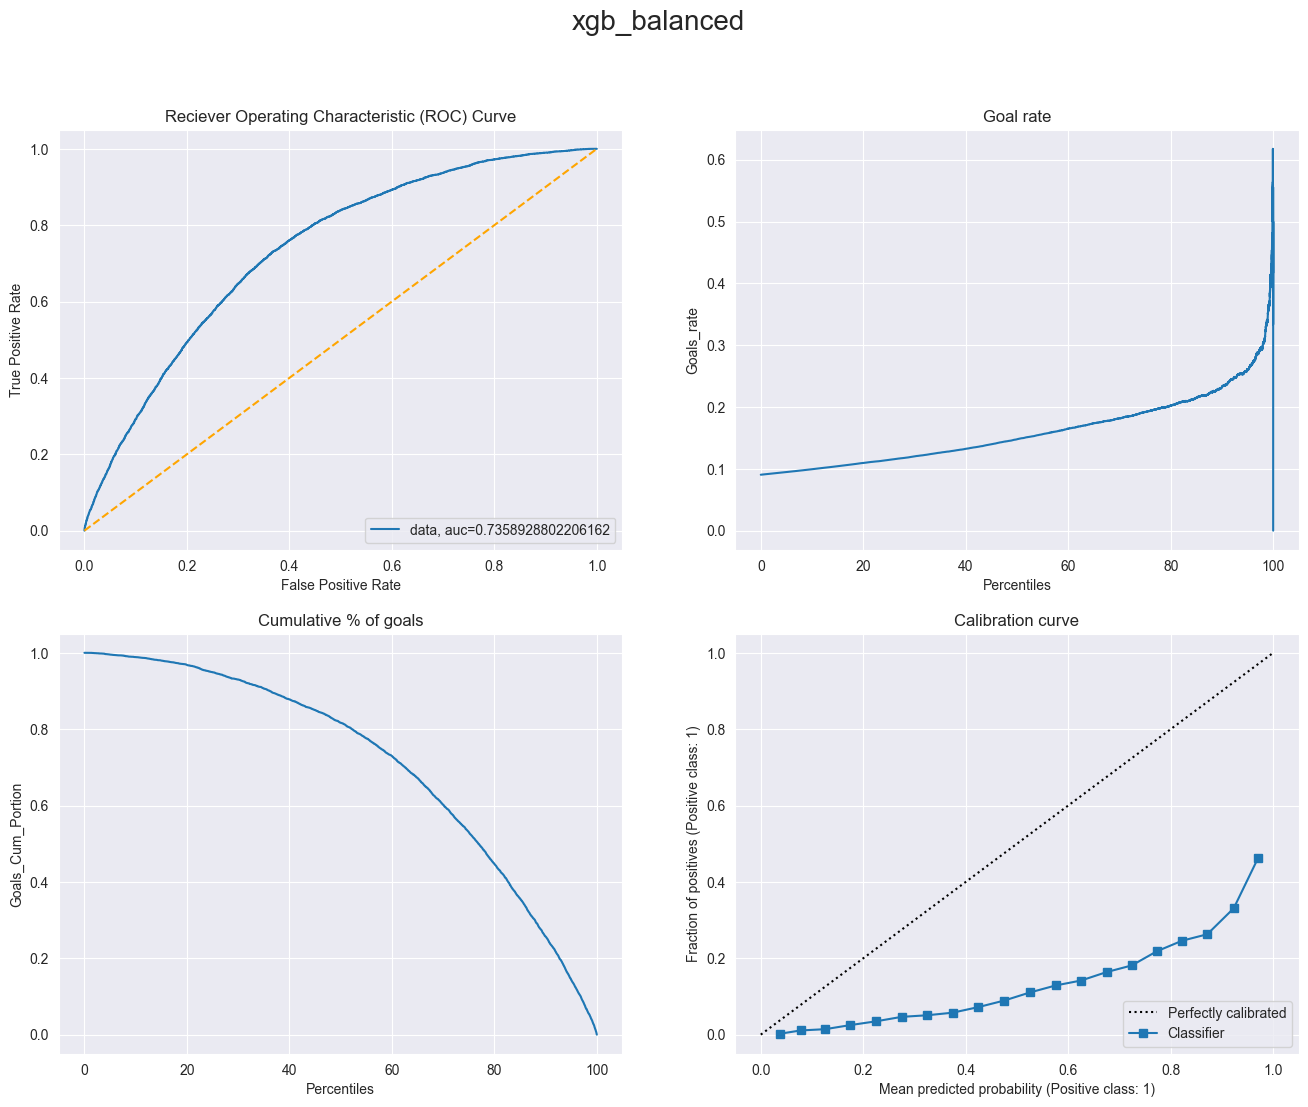

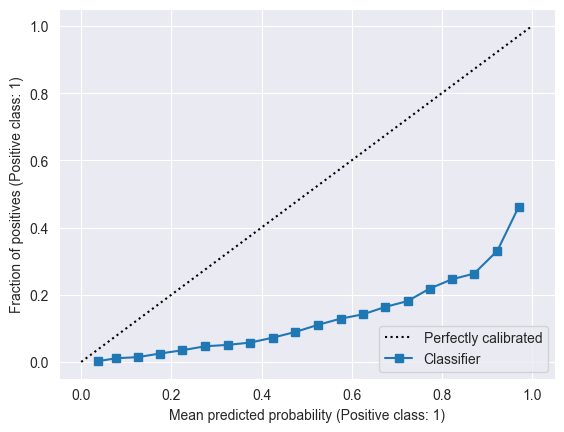

In [14]:
fig = generate_four_curves("xgb_balanced", y_test, classi.predict_proba(X_test)[:,1], 20)

f1 = metrics.f1_score(y_test, classi.predict(X_test), average='macro')
print(f"f1 score: {f1}")
#auc = metrics.roc_auc_score(y_test, classi.predict_proba(X_test)[:,1])
#exp.log_metric("accuracy", result_xgb)
#exp.log_metric("f1_score", f1)
#exp.log_metric("auc", auc)
#model_xgb.save_model("models/xgb_all_features.json")
#exp.log_model("XGB ALL", "models/xgb_all_features.json")
#exp.end()

In [16]:
print(metrics.classification_report(y_test, classi.predict(X_test)))

              precision    recall  f1-score   support

           0       0.96      0.64      0.77     54663
           1       0.17      0.72      0.27      5435

    accuracy                           0.65     60098
   macro avg       0.56      0.68      0.52     60098
weighted avg       0.89      0.65      0.72     60098



#### Use a new metric for hyperparameter search

In [17]:
def my_calibration_scorer(estimator,
                      X,
                      y,
                      n_bins=20
):
    """
    Implements the Expexted Calibration Error
    """

    y_prob = estimator.predict_proba(X)[:,1]

    bins = np.linspace(0.0, 1.0, n_bins + 1)

    binids = np.searchsorted(bins[1:-1], y_prob)

    bin_sums = np.bincount(binids, weights=y_prob, minlength=len(bins))
    bin_true = np.bincount(binids, weights=y, minlength=len(bins))
    bin_total = np.bincount(binids, minlength=len(bins))

    nonzero = bin_total != 0
    prob_true = bin_true[nonzero] / bin_total[nonzero]
    prob_pred = bin_sums[nonzero] / bin_total[nonzero]
    calibration_error = np.sum(np.abs(prob_true - prob_pred) * (bin_total[nonzero] / len(y)))

    return -calibration_error

In [18]:
from sklearn.model_selection import RandomizedSearchCV

tuned_parameters = {
  'gamma': np.linspace(0, 3, num=70),
  'max_depth': np.linspace(0, 10, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),

  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=250, scoring=my_calibration_scorer, cv=5,
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [19]:
print("Meilleur ensemble de paramètres trouvé")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé

{'max_depth': 6, 'max_delta_step': 0.0, 'gamma': 1.9565217391304348}
-0.0035781585518995275


Meilleur ensemble de paramètres trouvé

{'max_depth': 6, 'max_delta_step': 0.0, 'gamma': 1.9565217391304348}
-0.0035781585518995275

In [33]:
#model = grid_search.best_estimator_
model = xgb.XGBClassifier( max_delta_step = 0, gamma=1.9565217391304348, tree_method='gpu_hist')
model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=1.9565217391304348,
              gpu_id=0, grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=6, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=0, ...)

f1 score: 0.48586981519227884
 ece score: 0.0029295249859386135


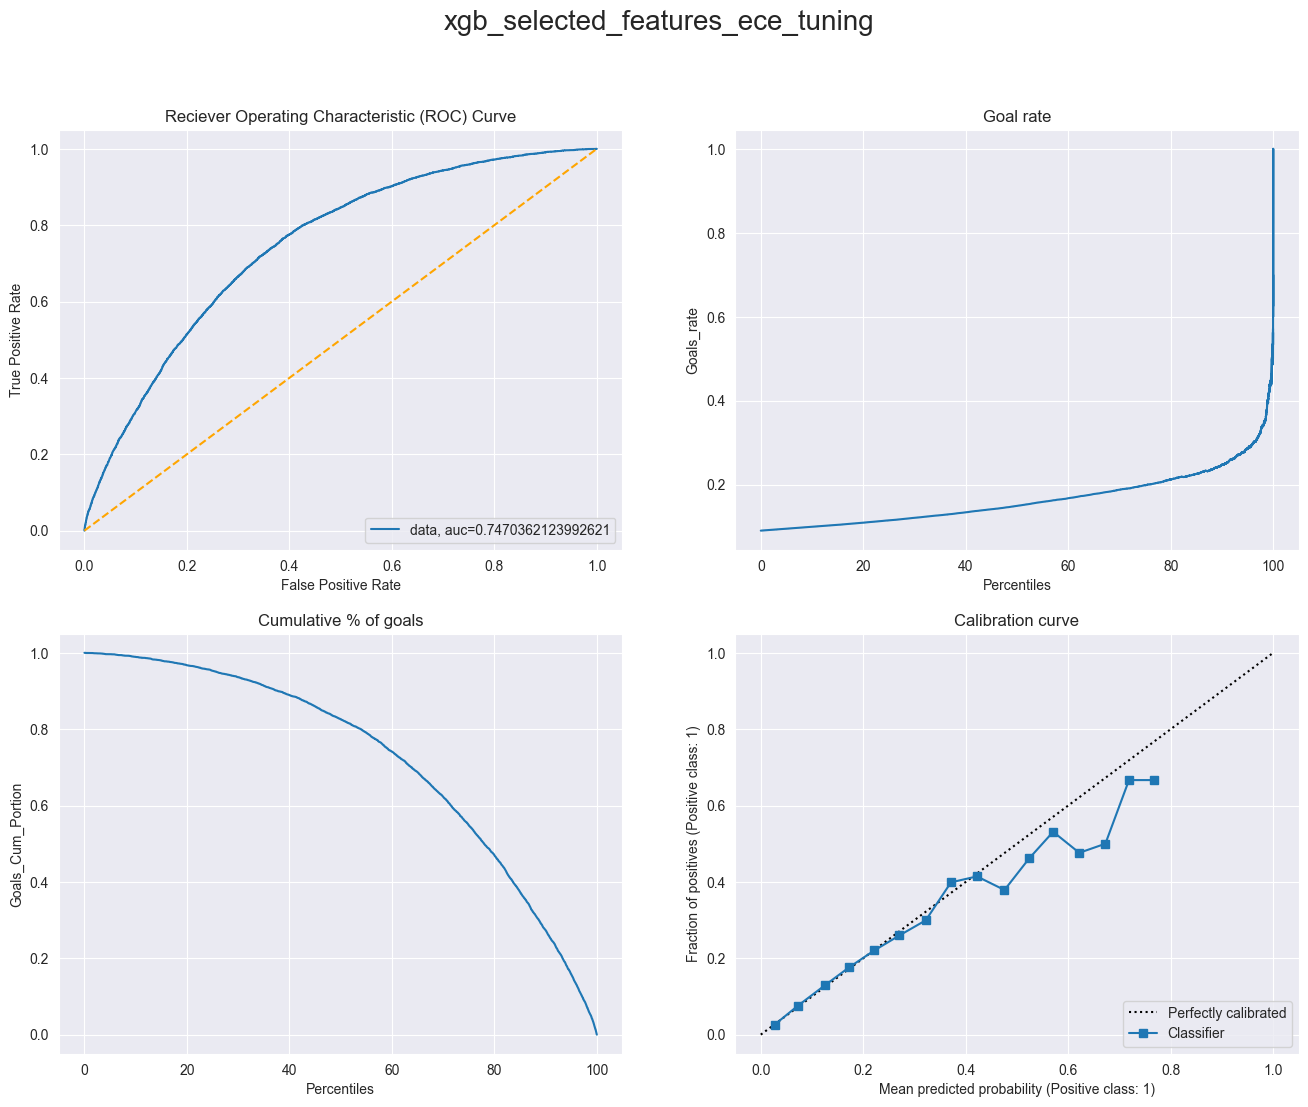

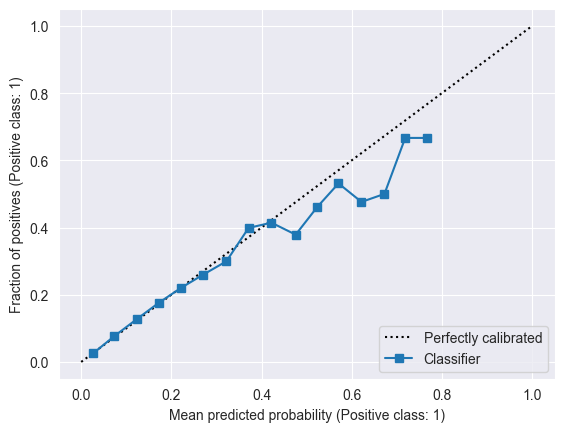

In [35]:
fig = generate_four_curves("xgb_selected_features_ece_tuning", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")

#### Different model: LDA

Unbalanced Training

In [22]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [23]:
#model = grid_search.best_estimator_
model = LinearDiscriminantAnalysis()
model.fit(X_train, y_train)


LinearDiscriminantAnalysis()

f1 score: 0.47716557660254494
 ece score: 0.009329585999716946


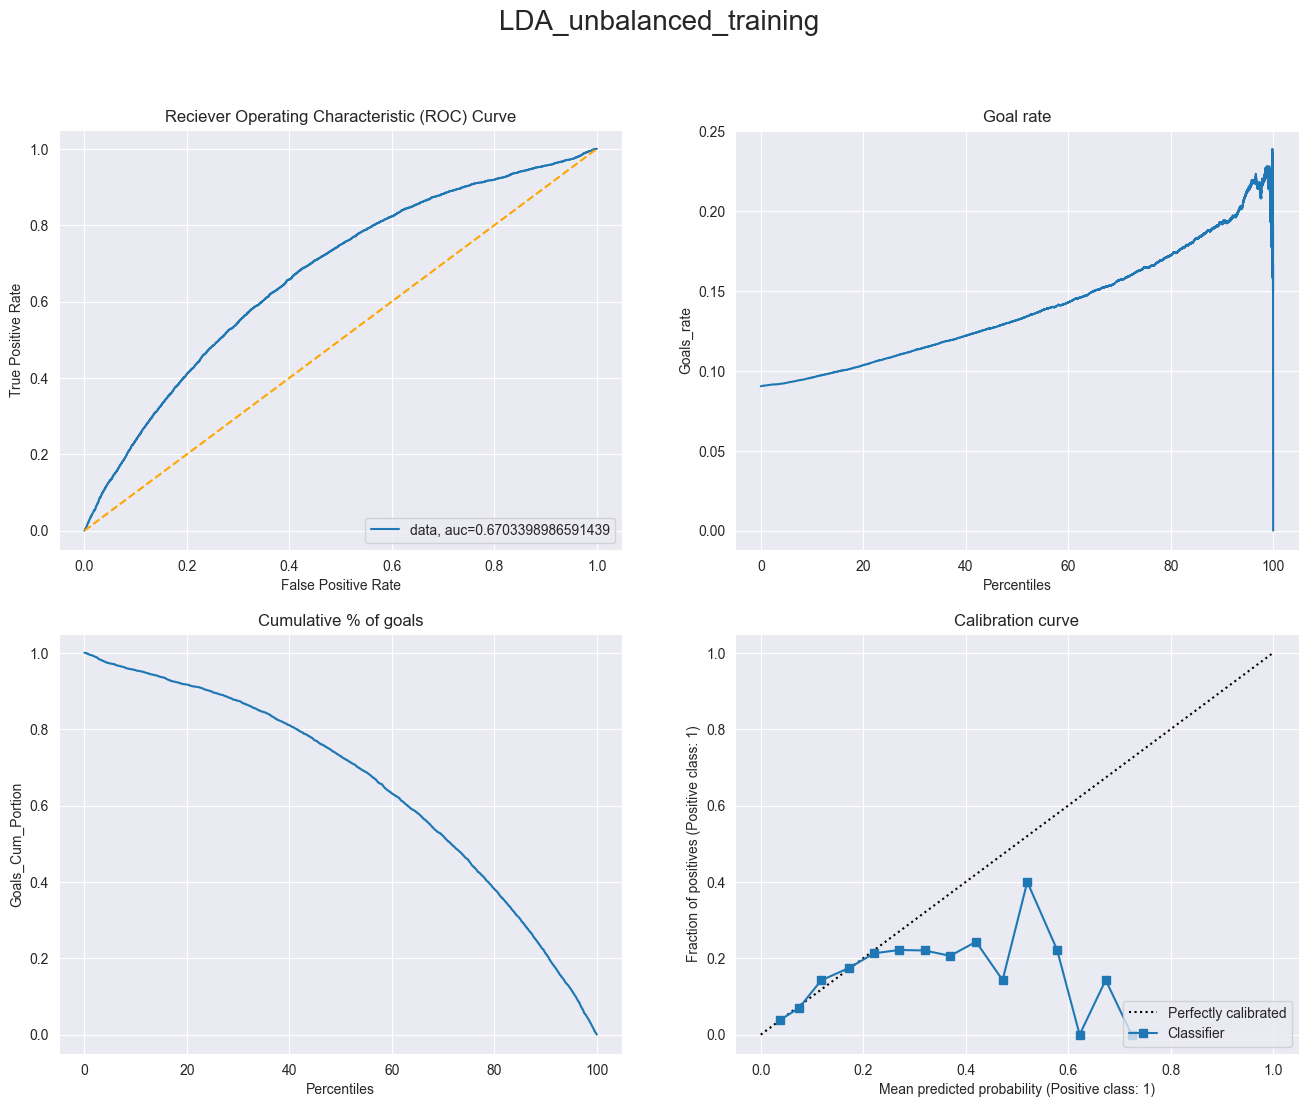

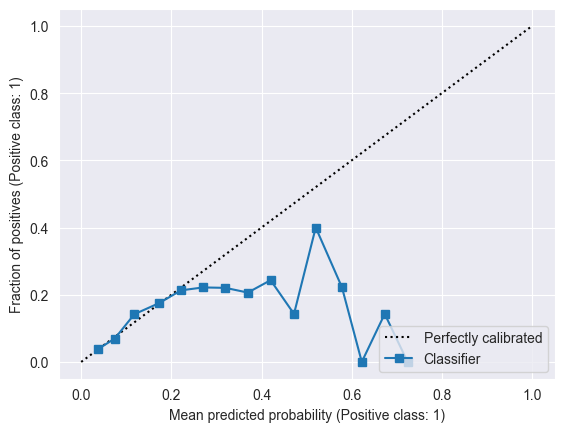

In [24]:
fig = generate_four_curves("LDA_unbalanced_training", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")

Balanced Training

In [25]:
#model = grid_search.best_estimator_
model = LinearDiscriminantAnalysis()
model.fit(X_train_balanced, y_train_balanced)


LinearDiscriminantAnalysis()

f1 score: 0.4933779798123561
 ece score: 0.38214112026178443


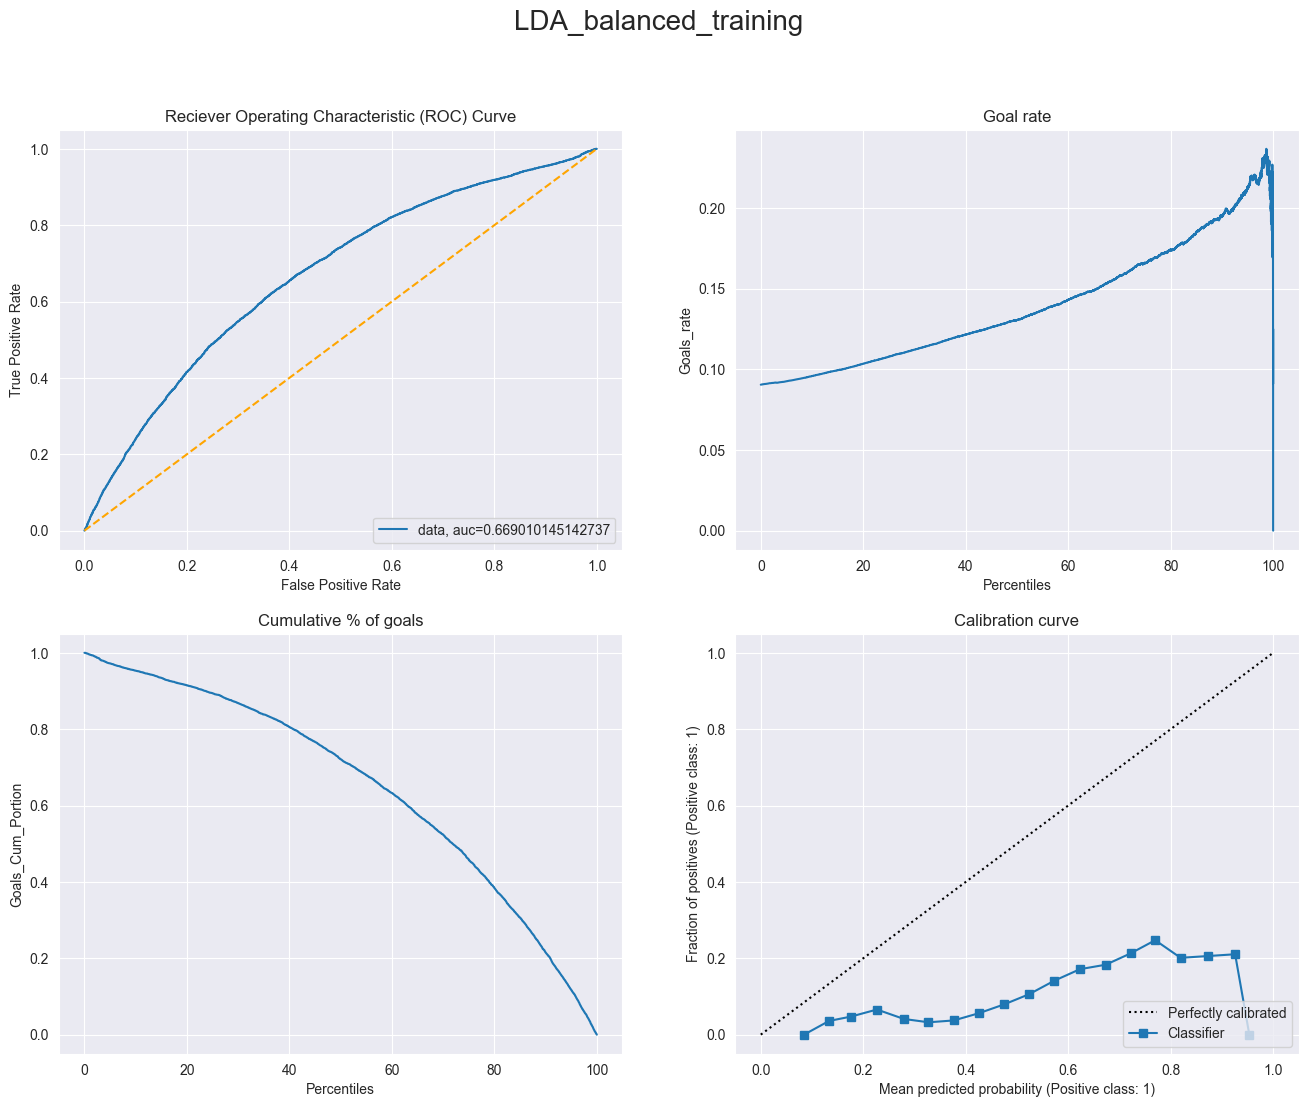

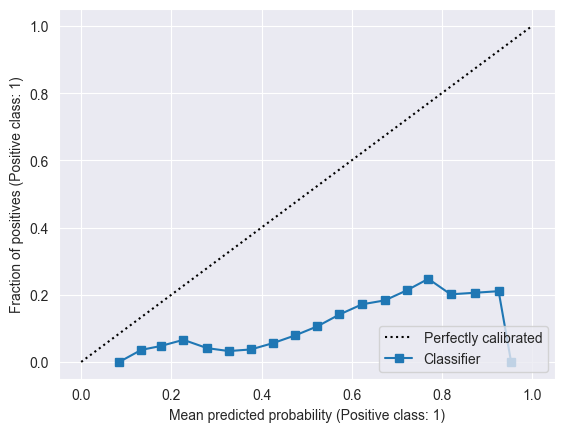

In [26]:
fig = generate_four_curves("LDA_balanced_training", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")

#### Different model: QDA

Unbalanced Training

In [27]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

In [28]:
#model = grid_search.best_estimator_
model = QuadraticDiscriminantAnalysis()
model.fit(X_train, y_train)


C:\Users\GM\.conda\envs\project\lib\site-packages\sklearn\discriminant_analysis.py:887: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


QuadraticDiscriminantAnalysis()

f1 score: 0.5389509995227864
 ece score: 0.10014463448907517


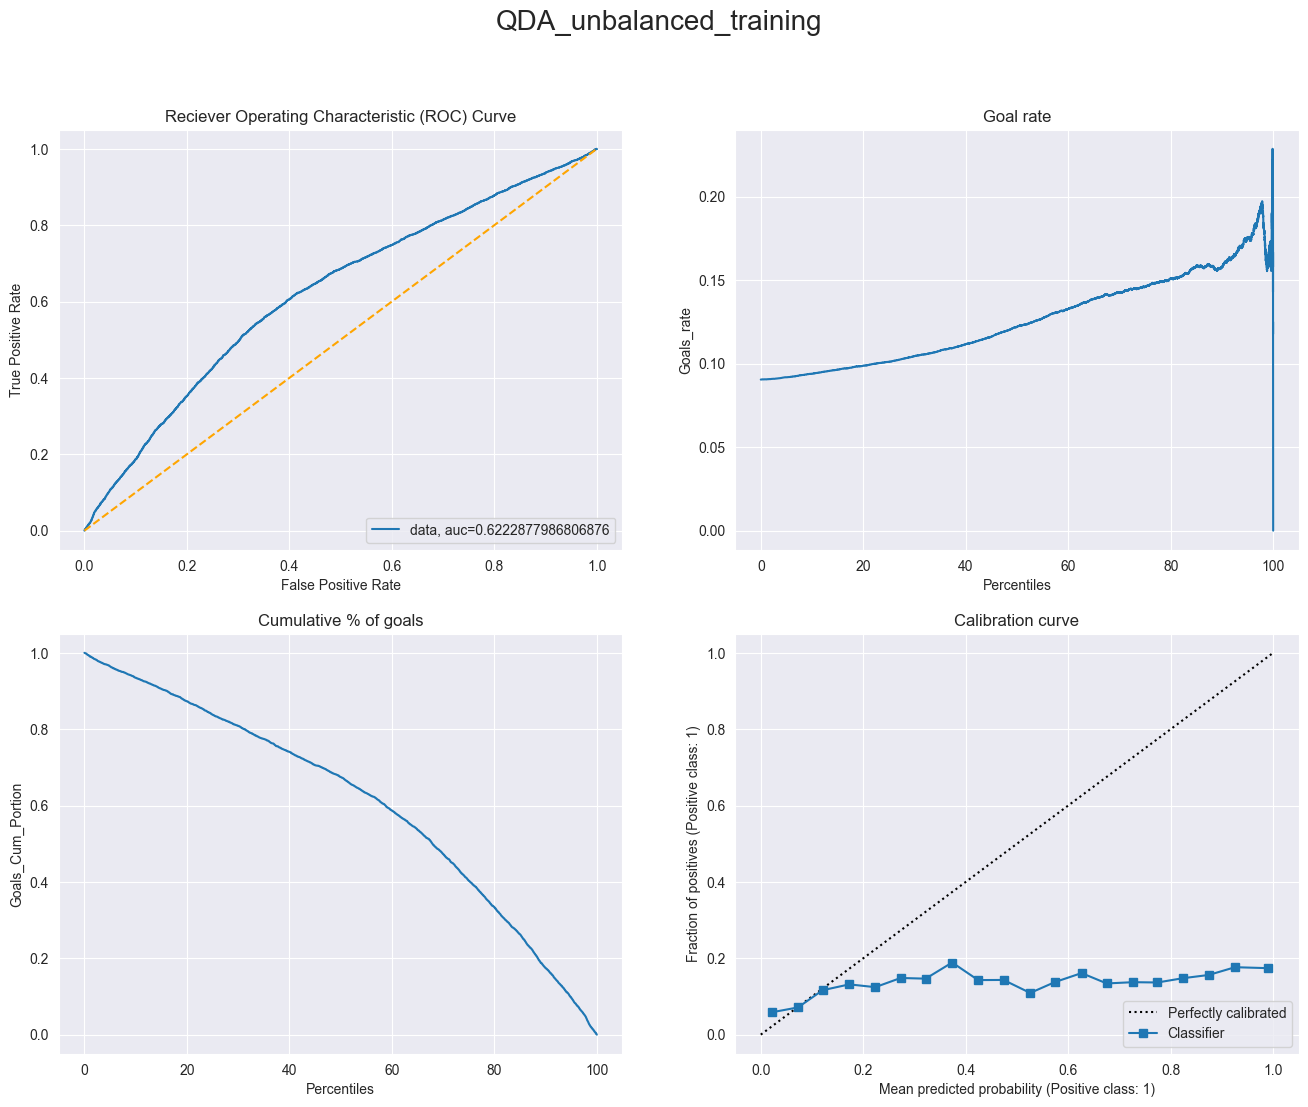

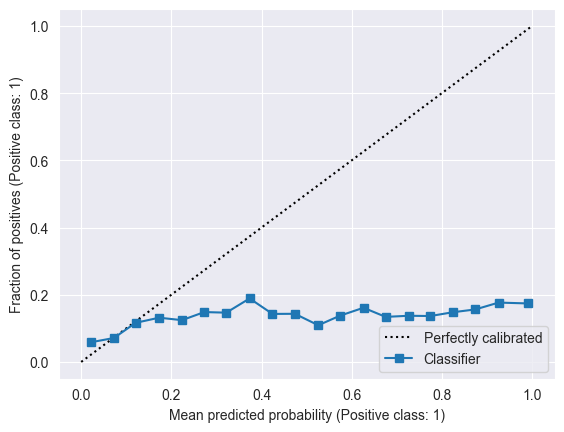

In [29]:
fig = generate_four_curves("QDA_unbalanced_training", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")

Balanced Training

In [30]:
#model = grid_search.best_estimator_
model = QuadraticDiscriminantAnalysis()
model.fit(X_train_balanced, y_train_balanced)


C:\Users\GM\.conda\envs\project\lib\site-packages\sklearn\discriminant_analysis.py:887: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


QuadraticDiscriminantAnalysis()

f1 score: 0.5126986055323604
 ece score: 0.33502799201902156


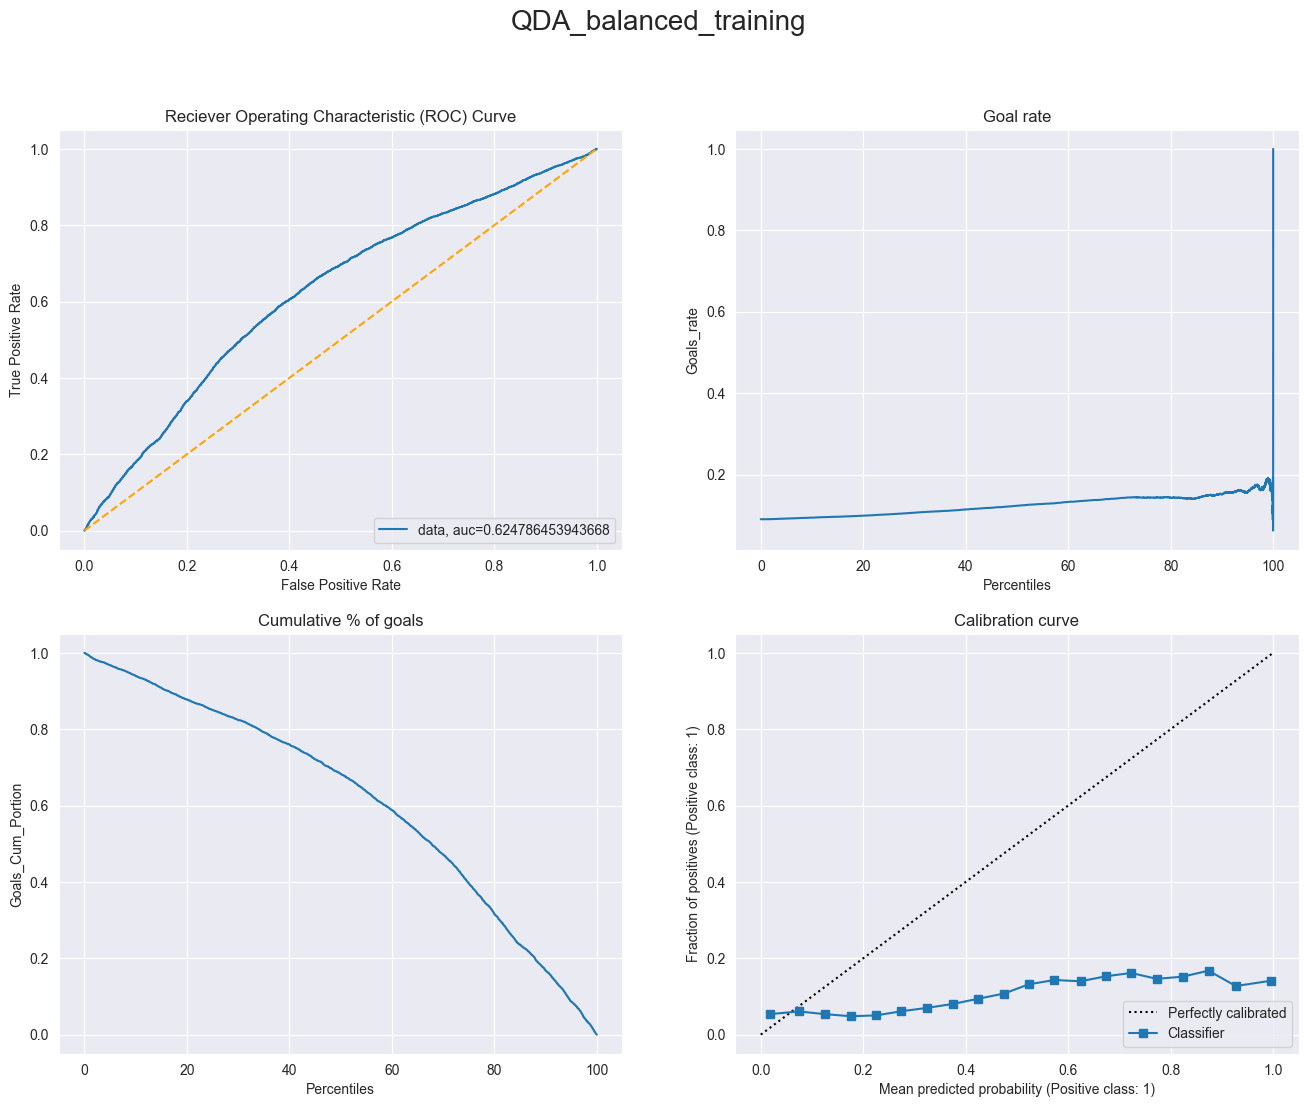

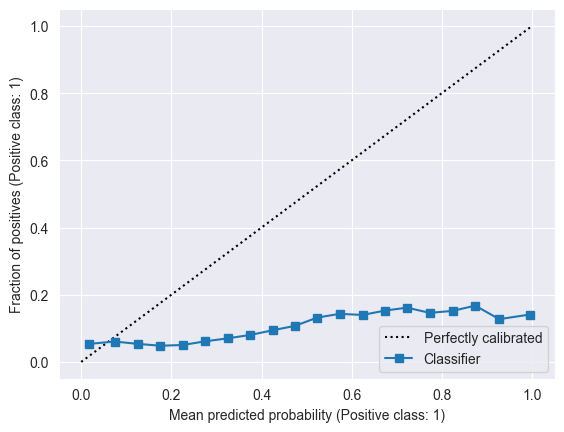

In [31]:
fig = generate_four_curves("QDA_balanced_training", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")

#### Different model: Neural Network

In [51]:
from sklearn.neural_network import MLPClassifier
model = MLPClassifier(
    max_iter=2000,
    activation="relu",
    solver="adam",
    verbose=True,
    #To be tuned
    hidden_layer_sizes=(300,100),
    alpha = 0.0001,
    batch_size = 100
)
model.fit(X_test, y_test)

Iteration 1, loss = 0.28589362
Iteration 2, loss = 0.27665661
Iteration 3, loss = 0.27571518
Iteration 4, loss = 0.27411907
Iteration 5, loss = 0.27385310
Iteration 6, loss = 0.27309512
Iteration 7, loss = 0.27271074
Iteration 8, loss = 0.27239476
Iteration 9, loss = 0.27162459
Iteration 10, loss = 0.27165482
Iteration 11, loss = 0.27108519
Iteration 12, loss = 0.27079397
Iteration 13, loss = 0.27081066
Iteration 14, loss = 0.27040891
Iteration 15, loss = 0.27045743
Iteration 16, loss = 0.26991960
Iteration 17, loss = 0.26980335
Iteration 18, loss = 0.26968524
Iteration 19, loss = 0.26908722
Iteration 20, loss = 0.26907341
Iteration 21, loss = 0.26873422
Iteration 22, loss = 0.26817143
Iteration 23, loss = 0.26802564
Iteration 24, loss = 0.26807521
Iteration 25, loss = 0.26797486
Iteration 26, loss = 0.26767064
Iteration 27, loss = 0.26751699
Iteration 28, loss = 0.26709836
Iteration 29, loss = 0.26687496
Iteration 30, loss = 0.26662091
Iteration 31, loss = 0.26644348
Iteration 32, los

MLPClassifier(batch_size=100, hidden_layer_sizes=(300, 100), max_iter=2000,
              verbose=True)

f1 score: 0.7257630098752456
 ece score: 0.007897537856328622


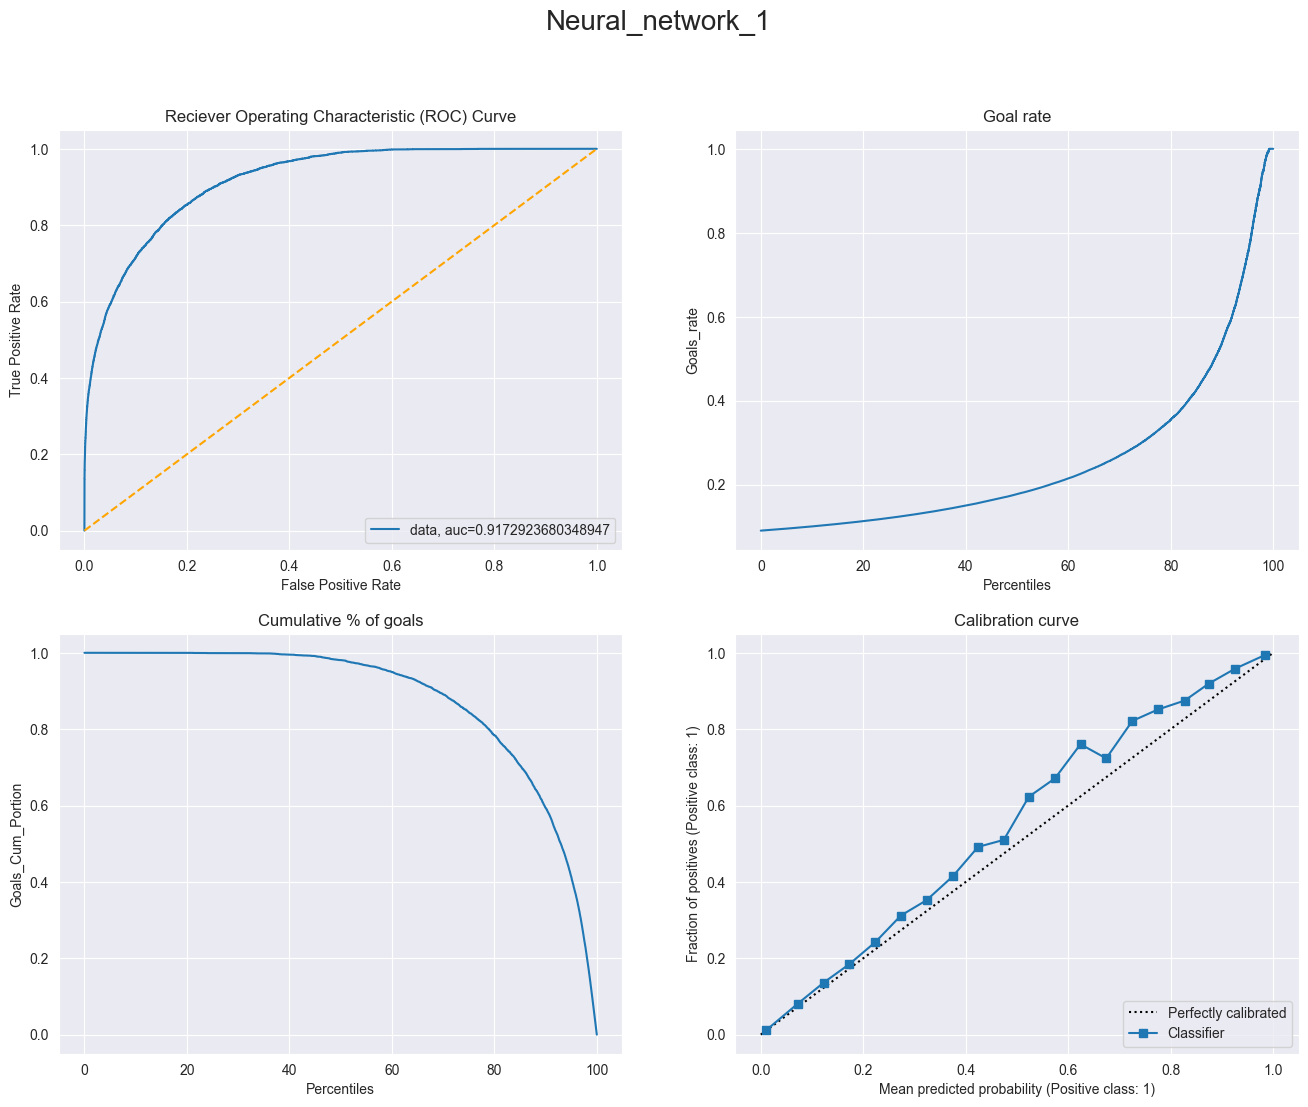

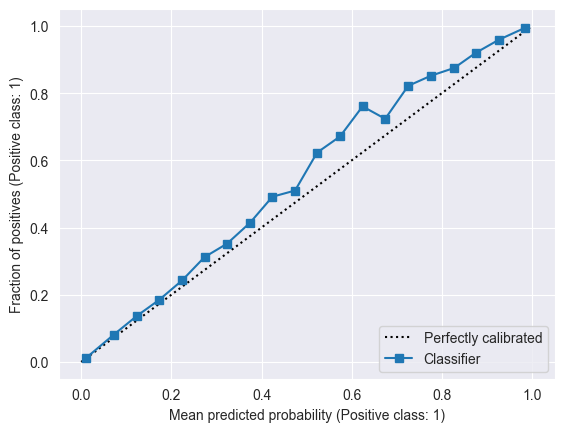

In [52]:
fig = generate_four_curves("Neural_network_1", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
ece = -my_calibration_scorer(model, X_test, y_test)
print(f"f1 score: {f1}")
print(f" ece score: {ece}")

#### New Model: Random forest classifier

In [57]:
from sklearn.ensemble import RandomForestClassifier

In [58]:
RandomForestClassifier().fit(X_train,y_train)

RandomForestClassifier()

In [ ]:
from sklearn.model_selection import GridSearchCV

tuned_parameters = {
    "n_estimators": np.linspace(50,200, 4, dtype=int),
    "min_samples_leaf": np.linspace(1,5, 5, dtype=int),
    "max_samples":[None,10000, 20000, 30000, 40000,  50000, 100000,150000,200000]
}

grid_search = GridSearchCV(
    RandomForestClassifier(), tuned_parameters,  scoring=my_calibration_scorer, cv=5,
)
grid_search.fit(X_train, y_train);




In [ ]:
print('Finished!')
print("Meilleur ensemble de paramètres trouvé")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

In [ ]:
#model = grid_search.best_estimator_
model = xgb.XGBClassifier(max_delta_step=0, gamma=1.9565217391304348, tree_method='gpu_hist')
model.fit(X_train, y_train)